# First experiment: DS-RNN vs DWB in the tame hallway

**What was run** (`run_experiment.sh`): 20 recorded episodes of each planner, back to back, in one Arena launch per
planner:

| | |
|---|---|
| World / scenario | `school_hallway` (60 × 12 m, 3 side corridors), `hallway_tame.json`: 20 pedestrians (walkers both ways, distracted, 2 runners at ~2.7 m/s, groups, corridor crossers) |
| Robot task | Jackal from (1, 6) to the goal at (59, 6); success = within 0.25 m of the goal position (heading ignored) |
| Planners | **DS-RNN** (learned, `nav2py_dsrnn_controller`, ≤ 1.0 m/s) and **DWB** (Nav2's classical default, ≤ 0.26 m/s) |
| Global planner | NavFn for both. Localization: ground truth. Episode timeout: 600 s |
| Mode | headless, real-time (RTF ≈ 1), CPU-only VM |

**Read the results with these caveats in mind:**
1. **Same scenario 20 times.** Start, goal and every pedestrian's route are identical in each episode; the only
   episode-to-episode variation is timing noise in the simulator. So the confidence intervals describe *this one
   scenario*, not crowds in general. A real benchmark would randomise scenarios (different seeds / densities).
2. **Asymmetric perception (on purpose).** DS-RNN gets every pedestrian's exact position from HuNav; DWB only sees
   people as lidar obstacles in its costmap.
3. **Different speed limits.** DWB's own config caps it at 0.26 m/s, DS-RNN at 1.0 m/s. Time-to-goal mostly reflects that.
4. **Pedestrians treat the robot as an obstacle, not as a person.** HuNav's social force pushes them away from the
   robot's body like from a wall, but they don't anticipate its motion, yield, or react socially (HuNav's robot
   tracking is disabled). Fast walkers (the runners) can't avoid it in time.

Everything below is computed from the recorded positions (`social_metrics.py`), identically for both planners.

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display

from arena_analysis import load_run
import social_metrics as sm
import plots

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 2)

DATA = Path("data")
N = 20   # episodes per planner

## 1. Load the recordings

Each planner's launch wrote one *run* folder (`data/<time>_<planner>_hallway_tame/`) with one sub-folder per episode.
We take the newest run per planner and keep the first `N` finished episodes (the last one was cut off when the sim
was stopped and is labelled `incomplete`).

In [2]:
episodes = {}
for planner in ["dsrnn", "dwb"]:
    run_dir = sorted(DATA.glob(f"*_{planner}_*"))[-1]
    run = load_run(run_dir)
    done = [ep for ep in run.episodes if ep.meta.get("outcome") != "incomplete"][:N]
    episodes[planner] = done
    print(f"{planner}: {len(done)} episodes from {run_dir.name}")

dsrnn: 20 episodes from 20261011-024722_dsrnn_hallway_tame
dwb: 20 episodes from 20261011-032147_dwb_hallway_tame


## 2. One row per episode

`sm.episode_metrics(ep)` returns ~40 numbers per episode. The most useful ones:

| column | meaning |
|---|---|
| `success` | Nav2 reported the goal reached (else `timeout` / `aborted`) |
| `time_to_goal` | seconds until the robot was within the goal tolerance |
| `path_efficiency` | straight-line distance / distance driven (1 = perfectly straight) |
| `collisions` | number of robot-pedestrian **contacts** (bodies overlapping: centre distance < robot radius 0.27 m + pedestrian radius 0.35 m) |
| `min_clearance` | closest the robot's body came to any pedestrian's body (m; negative = overlap) |
| `min_ttc` | smallest **time-to-collision**: if everyone kept their velocity, how many seconds until a contact. Below ~1 s is dangerous |
| `time_ttc_danger` | seconds with TTC < 1 s (imminent-collision situations, even if they were resolved) |
| `time_intimate` / `time_personal` | seconds with the closest pedestrian in the intimate (< 0.45 m) / personal (0.45–1.2 m) zone |
| `n_freezes`, `freeze_time` | robot standing still (< 0.05 m/s for ≥ 1 s) after it first started moving, before reaching the goal |
| `froze_in_crowd` | at least one of those freezes happened with a pedestrian within 2 m (the "freezing robot problem") |
| `mean_abs_jerk` | average jerk (m/s³), how abrupt the speed changes are |
| `heading_per_m` | total turning per metre driven (rad/m), "path irregularity" |
| `omega_flips_per_min` | how often the turn command switches direction per minute: weaving / oscillation |

In [3]:
table = pd.DataFrame([{**sm.episode_metrics(ep), "planner": p} for p, eps in episodes.items() for ep in eps])
cols = ["planner", "episode", "outcome", "time_to_goal", "path_efficiency", "collisions", "min_clearance", "min_ttc",
        "time_ttc_danger", "frac_intimate", "n_freezes", "froze_in_crowd", "mean_abs_jerk", "omega_flips_per_min"]
table[cols]

,planner,episode,outcome,time_to_goal,path_efficiency,collisions,min_clearance,min_ttc,time_ttc_danger,frac_intimate,n_freezes,froze_in_crowd,mean_abs_jerk,omega_flips_per_min
0,dsrnn,0,success,67.87,0.92,0,1.72e-01,3.20e-01,2.80,7.26e-02,0,False,1.00,91.15
1,dsrnn,1,success,73.89,0.86,0,9.74e-02,1.41e-01,4.00,8.02e-02,0,False,0.99,80.57
2,dsrnn,2,success,71.33,0.87,0,1.45e-01,2.29e-01,3.00,4.56e-02,0,False,0.93,93.28
3,dsrnn,3,success,71.40,0.91,2,-5.27e-02,0.00e+00,5.39,1.03e-01,0,False,1.05,83.20
4,dsrnn,4,success,72.59,0.89,2,-6.66e-02,0.00e+00,5.29,8.66e-02,0,False,1.15,79.95
5,dsrnn,5,success,74.36,0.88,2,-8.59e-02,0.00e+00,6.69,1.05e-01,0,False,1.15,77.20
6,dsrnn,6,success,70.10,0.87,0,1.10e-01,1.49e-01,3.10,4.45e-02,0,False,0.91,86.41
7,dsrnn,7,success,61.01,0.96,0,5.32e-03,6.83e-03,3.30,4.04e-02,0,False,0.76,90.68
8,dsrnn,8,success,78.59,0.81,0,1.25e-01,3.08e-01,3.40,7.55e-02,0,False,1.00,73.48
9,dsrnn,9,success,72.53,0.86,0,1.47e-01,2.23e-01,2.40,4.09e-02,0,False,0.89,89.51


## 3. Headline comparison

Rates (fraction of episodes) come with a 95% **Wilson** interval; averages with a 95% **bootstrap** interval
(resampling episodes). Overlapping intervals mean the difference may just be noise.

In [4]:
sm.compare(table)

,dsrnn,dwb
episodes,20,20
success rate,"0.95 [0.76, 0.99]","1.00 [0.84, 1.00]"
collided rate,"0.30 [0.15, 0.52]","0.30 [0.15, 0.52]"
froze rate,"0.15 [0.05, 0.36]","0.00 [0.00, 0.16]"
froze_in_crowd rate,"0.05 [0.01, 0.24]","0.00 [0.00, 0.16]"
wall_collision rate,"0.00 [0.00, 0.16]","0.00 [0.00, 0.16]"
time_to_goal,"71.29 [69.50, 73.01]","256.24 [254.79, 257.82]"
path_length,"65.70 [64.58, 66.82]","60.13 [59.91, 60.36]"
path_efficiency,"0.89 [0.87, 0.90]","0.96 [0.96, 0.97]"
mean_speed,"0.86 [0.78, 0.91]","0.23 [0.23, 0.23]"


### Are the differences real?

`plots.significance` runs **Fisher's exact test** on the rates and the **Mann-Whitney U test** on the per-episode
values (it compares the distributions without assuming they're normal). p < 0.05 is the conventional threshold.
With this many metrics, one "significant" result in twenty can be luck. And remember caveat 1: "significant" here
means "reproducibly different *on this scenario*".

In [5]:
plots.significance(table, "dsrnn", "dwb")

,metric,dsrnn,dwb,test,p,significant
0,success rate,19/20,20/20,Fisher,1.00e+00,False
1,collided rate,6/20,6/20,Fisher,1.00e+00,False
2,froze rate,3/20,0/20,Fisher,2.31e-01,False
3,froze_in_crowd rate,1/20,0/20,Fisher,1.00e+00,False
4,wall_collision rate,0/20,0/20,Fisher,1.00e+00,False
5,time_to_goal,71.36,256.24,Mann-Whitney (medians),6.80e-08,True
6,path_length,66.49,59.99,Mann-Whitney (medians),1.43e-07,True
7,path_efficiency,0.88,0.97,Mann-Whitney (medians),2.17e-07,True
8,mean_speed,0.90,0.23,Mann-Whitney (medians),1.20e-06,True
9,collisions,0.00,0.00,Mann-Whitney (medians),8.54e-01,False


## 4. Task performance: does it get there, and how directly?

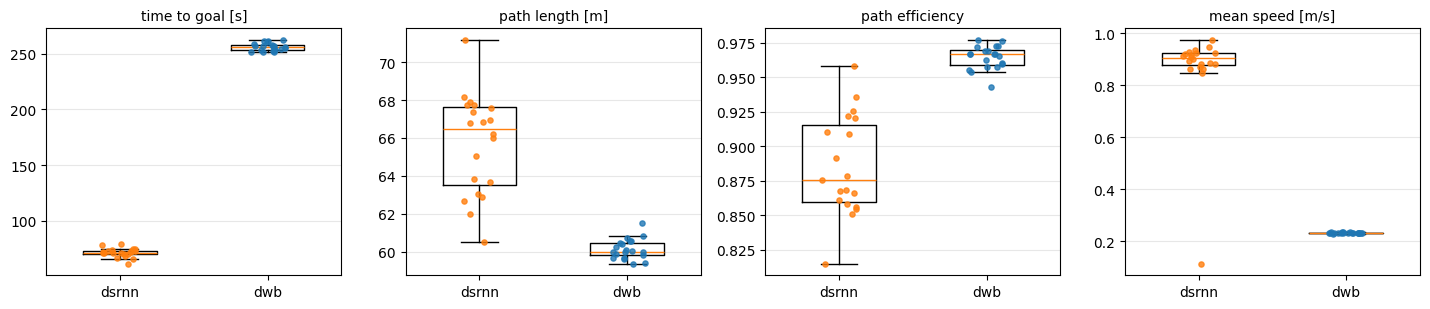

In [6]:
plots.distributions(table, ["time_to_goal", "path_length", "path_efficiency", "mean_speed"],
                    labels={"time_to_goal": "time to goal [s]", "path_length": "path length [m]",
                            "path_efficiency": "path efficiency", "mean_speed": "mean speed [m/s]"});

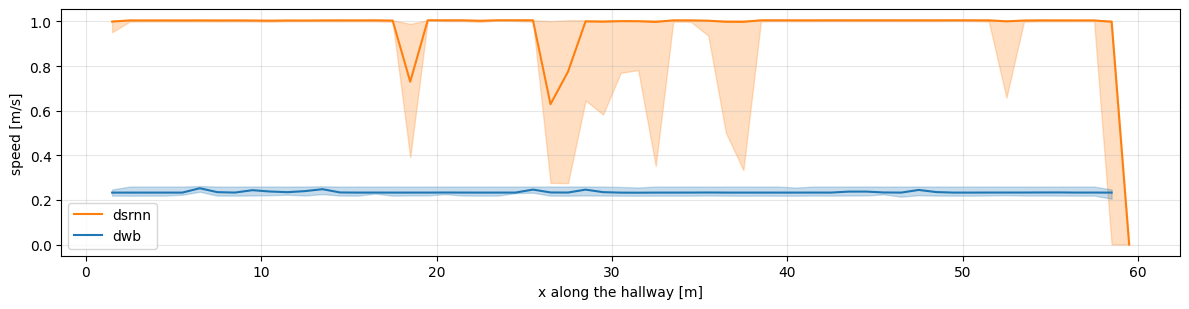

In [7]:
plots.speed_profile(episodes);

The speed profile shows *where* each planner slows down. Dips line up with the crowd: the side corridors at x ≈ 15,
30 and 45 m are where crossers enter, and where the two groups meet the robot.

## 5. Safety: collisions, near-misses, time-to-collision

**Collision rate** (fraction of episodes with ≥ 1 contact) is the standard headline. The details matter more,
though: *when* and *where* contacts happen, and *who moved into whom*. A robot that drives into people is a very
different failure from one that stands still and gets walked into (remember: these pedestrians never yield).

In [8]:
contacts = pd.concat([sm.contact_events(ep).assign(planner=p, episode=ep.meta["episode"])
                      for p, eps in episodes.items() for ep in eps], ignore_index=True)
print("contacts per planner:", contacts.groupby("planner").size().to_dict())
contacts[["planner", "episode", "name", "t_rel", "x", "y", "duration", "min_clearance",
          "robot_speed", "human_speed", "robot_toward", "human_toward", "robot_active"]]

contacts per planner: {'dsrnn': 10, 'dwb': 8}


,planner,episode,name,t_rel,x,y,duration,min_clearance,robot_speed,human_speed,robot_toward,human_toward,robot_active
0,dsrnn,3,runner_0,18.08,18.75,6.21,0.1,-4.13e-02,0.66,0.31,0.54,1.84e-01,True
1,dsrnn,3,runner_1,43.09,34.96,7.69,0.3,-5.27e-02,0.73,0.24,0.72,5.29e-03,True
2,dsrnn,4,runner_0,17.98,18.69,6.19,0.2,-6.66e-02,0.92,0.62,0.83,4.28e-01,True
3,dsrnn,4,runner_1,42.39,36.52,7.86,0.2,-5.29e-02,0.74,0.23,0.61,9.33e-02,True
4,dsrnn,5,runner_0,18.08,18.59,6.34,0.6,-4.44e-02,0.51,0.39,0.51,3.88e-01,True
5,dsrnn,5,runner_1,44.26,31.77,7.82,0.4,-8.59e-02,0.89,0.91,0.89,8.75e-01,True
6,dsrnn,10,runner_0,47.49,36.47,6.14,0.0,-1.89e-02,0.77,0.33,0.40,1.02e-01,True
7,dsrnn,10,runner_1,42.86,35.57,7.87,0.2,-1.06e-02,0.63,0.81,0.62,-3.09e-01,True
8,dsrnn,11,runner_1,44.16,32.16,8.06,0.1,-2.51e-02,0.87,0.58,0.69,-1.11e-01,True
9,dsrnn,19,runner_0,18.05,18.64,6.21,0.1,-1.98e-02,0.51,0.39,0.46,2.79e-01,True


Which pedestrian classes the robot touches (names come from the scenario spec):


cls,runner
planner,
dsrnn,10
dwb,8


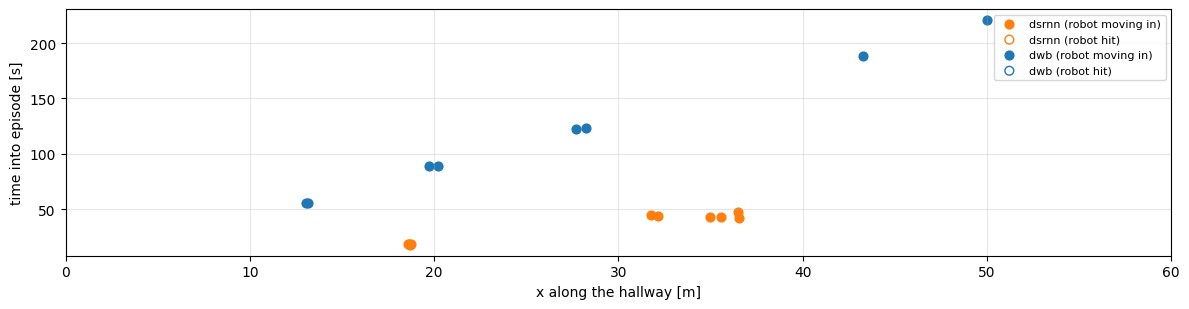

In [9]:
if len(contacts):
    plots.contacts_overview(contacts)
    print("Which pedestrian classes the robot touches (names come from the scenario spec):")
    display(contacts.assign(cls=contacts["name"].str.replace(r"_\d+$", "", regex=True))
                    .groupby(["planner", "cls"]).size().unstack(fill_value=0))

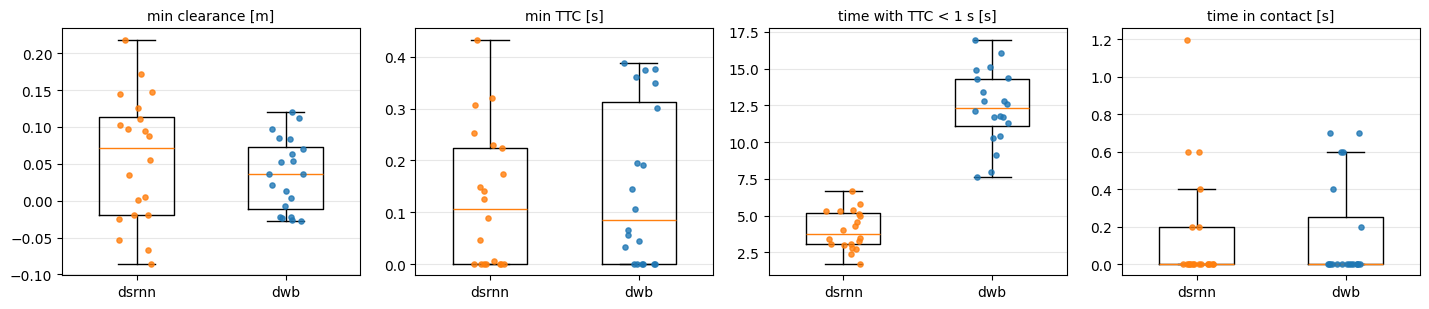

In [10]:
plots.distributions(table, ["min_clearance", "min_ttc", "time_ttc_danger", "collision_time"],
                    labels={"min_clearance": "min clearance [m]", "min_ttc": "min TTC [s]",
                            "time_ttc_danger": "time with TTC < 1 s [s]", "collision_time": "time in contact [s]"});

### One episode up close

Closest-pedestrian clearance over an episode (black), with the proxemic zones shaded (red = contact, orange =
intimate, yellow = personal, green = social) and the time-to-collision (purple). Each dip is one encounter. We show
the episode with the smallest clearance for each planner.

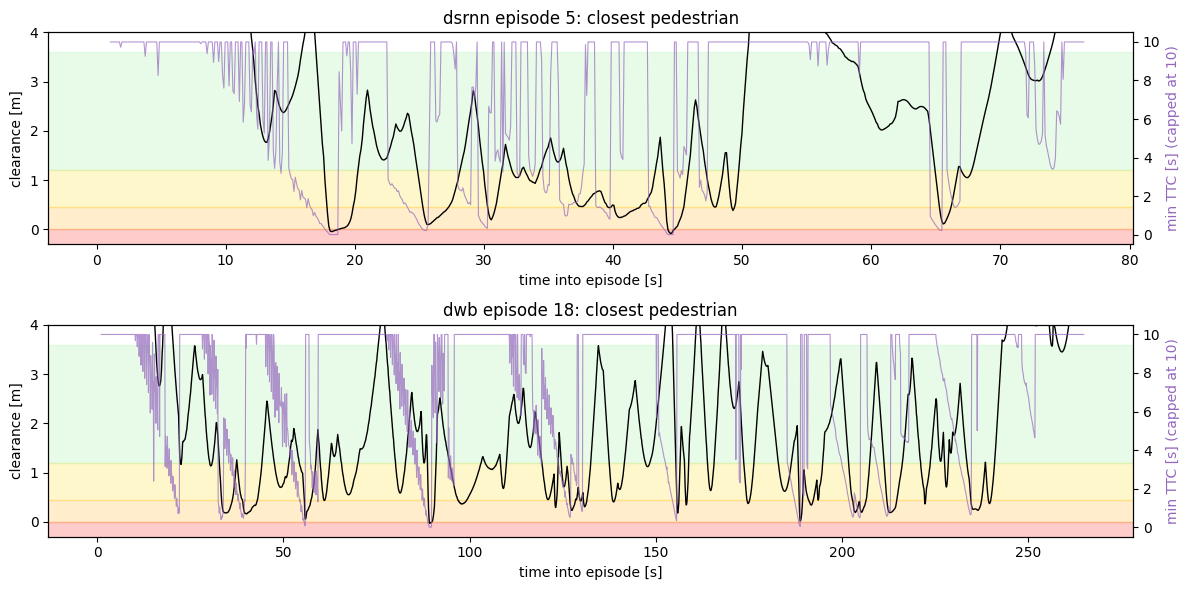

In [11]:
fig, axes = plt.subplots(len(episodes), 1, figsize=(12, 3 * len(episodes)))
for ax, (planner, eps) in zip(np.atleast_1d(axes), episodes.items()):
    worst = min(eps, key=lambda e: table.loc[(table.planner == planner) & (table.episode == e.meta["episode"]),
                                             "min_clearance"].iloc[0])
    plots.clearance_timeline(worst, ax=ax)
fig.tight_layout()

## 6. Comfort: proxemics

Even without contact, passing within ~0.45 m of someone (their *intimate* zone) is uncomfortable, and 0.45–1.2 m
(*personal* zone) is where people expect only acquaintances. Social-navigation papers report time or fraction of
time in these zones. Faster robots spend fewer *seconds* near people simply because they finish sooner, so the
fair comparison is the **fraction** of the episode (`frac_*` columns).

,frac_contact,frac_intimate,frac_personal,frac_social,duration
planner,,,,,
dsrnn,2.15e-03,0.07,0.13,0.39,99.07
dwb,6.12e-04,0.16,0.24,0.43,258.27


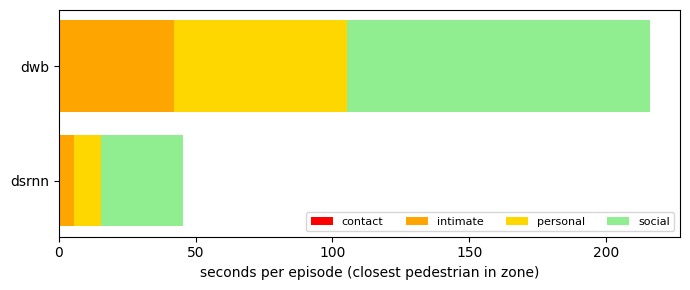

In [12]:
plots.proxemic_bars(table)
table.groupby("planner")[["frac_contact", "frac_intimate", "frac_personal", "frac_social", "duration"]].mean()

## 7. Freezing

The **freezing robot problem**: in dense crowds, planners often decide every option is unsafe and stop. In
the real world that causes deadlocks, because people expect the robot to move. Here a freeze is ≥ 1 s below
0.05 m/s before the goal, counted only after the robot first started moving (after each reset the robot waits
~1–2 s for Nav2's first plan; that is not a freeze). `near_people` marks freezes with a pedestrian within 2 m. A
freeze far from everyone means something else went wrong (e.g. pinned against a wall, or a planning failure).

In [13]:
fr = pd.concat([sm.freezes(ep).assign(planner=p, episode=ep.meta["episode"])
                for p, eps in episodes.items() for ep in eps], ignore_index=True)
print("episodes with a freeze:", table.groupby("planner")["froze"].sum().to_dict(),
      "  of which near people:", table.groupby("planner")["froze_in_crowd"].sum().to_dict())
fr

episodes with a freeze: {'dsrnn': 3, 'dwb': 0}   of which near people: {'dsrnn': 1, 'dwb': 0}


,t_rel,duration,x,y,nearest_clearance,near_people,planner,episode
0,44.96,2.6,32.55,8.10,0.70,True,dsrnn,11
1,72.00,529.4,59.80,5.34,5.24,False,dsrnn,14
2,9.42,1.8,10.13,6.09,6.20,False,dsrnn,18


## 8. Smoothness: how the motion looks

Jerky, weaving motion is unpleasant to be around and hard for people to predict. DS-RNN's ±1 rad/s "bang-bang"
steering (its turn output always saturates the ±0.1 rad/step clip) should show up as many direction flips per
minute.

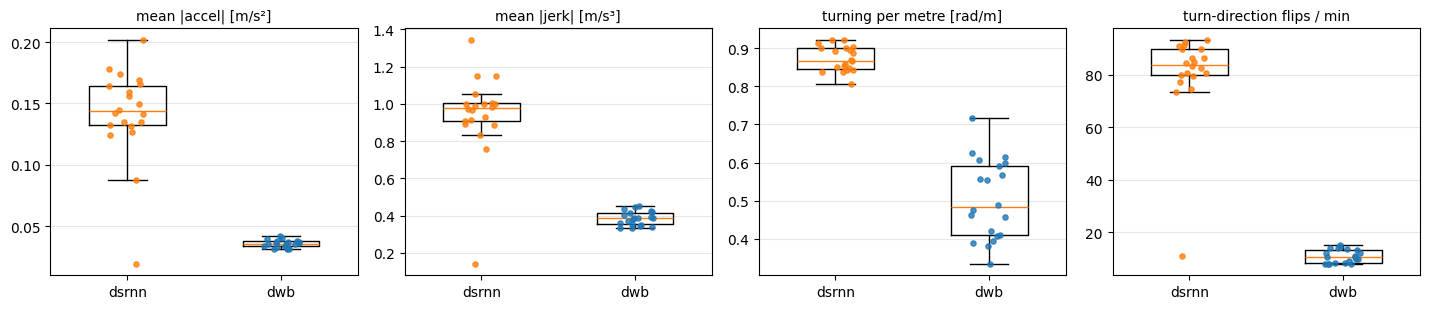

In [14]:
plots.distributions(table, ["mean_abs_accel", "mean_abs_jerk", "heading_per_m", "omega_flips_per_min"],
                    labels={"mean_abs_accel": "mean |accel| [m/s²]", "mean_abs_jerk": "mean |jerk| [m/s³]",
                            "heading_per_m": "turning per metre [rad/m]",
                            "omega_flips_per_min": "turn-direction flips / min"});

## 9. All paths at once

Every episode's path per planner. Red × = contact, blue ○ = freeze. Because the scenario is identical in every
episode, a tight bundle of paths means the planner behaves consistently. The spread shows how much timing noise
changes its decisions.

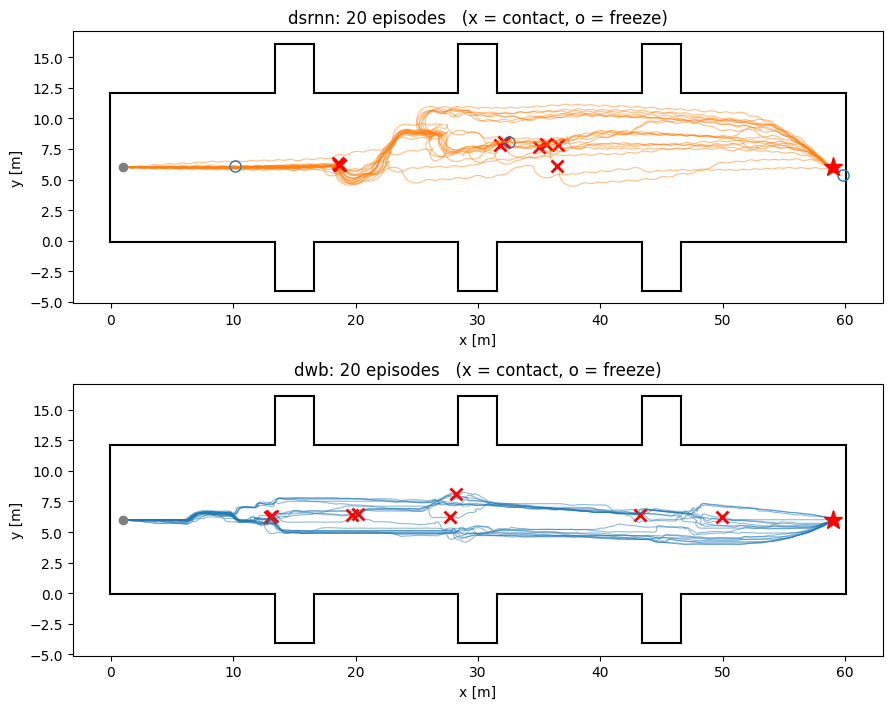

In [15]:
plots.trajectories(episodes);

## 10. Watch some episodes

Static frames first: the moment of each planner's first contact (follow view, 16 m window around the robot).
Then videos of a **typical** episode (median time to goal) and the **worst** episode (most contacts, then smallest
clearance) per planner. Rendering takes ~0.3 s per frame, so videos are rendered once into `media/` and reused.

Legend in the frames: orange = robot (arrow = heading, line = path so far), numbered circles = pedestrians with
velocity arrows (red when touching the robot), green dashed = global plan, red star = goal.

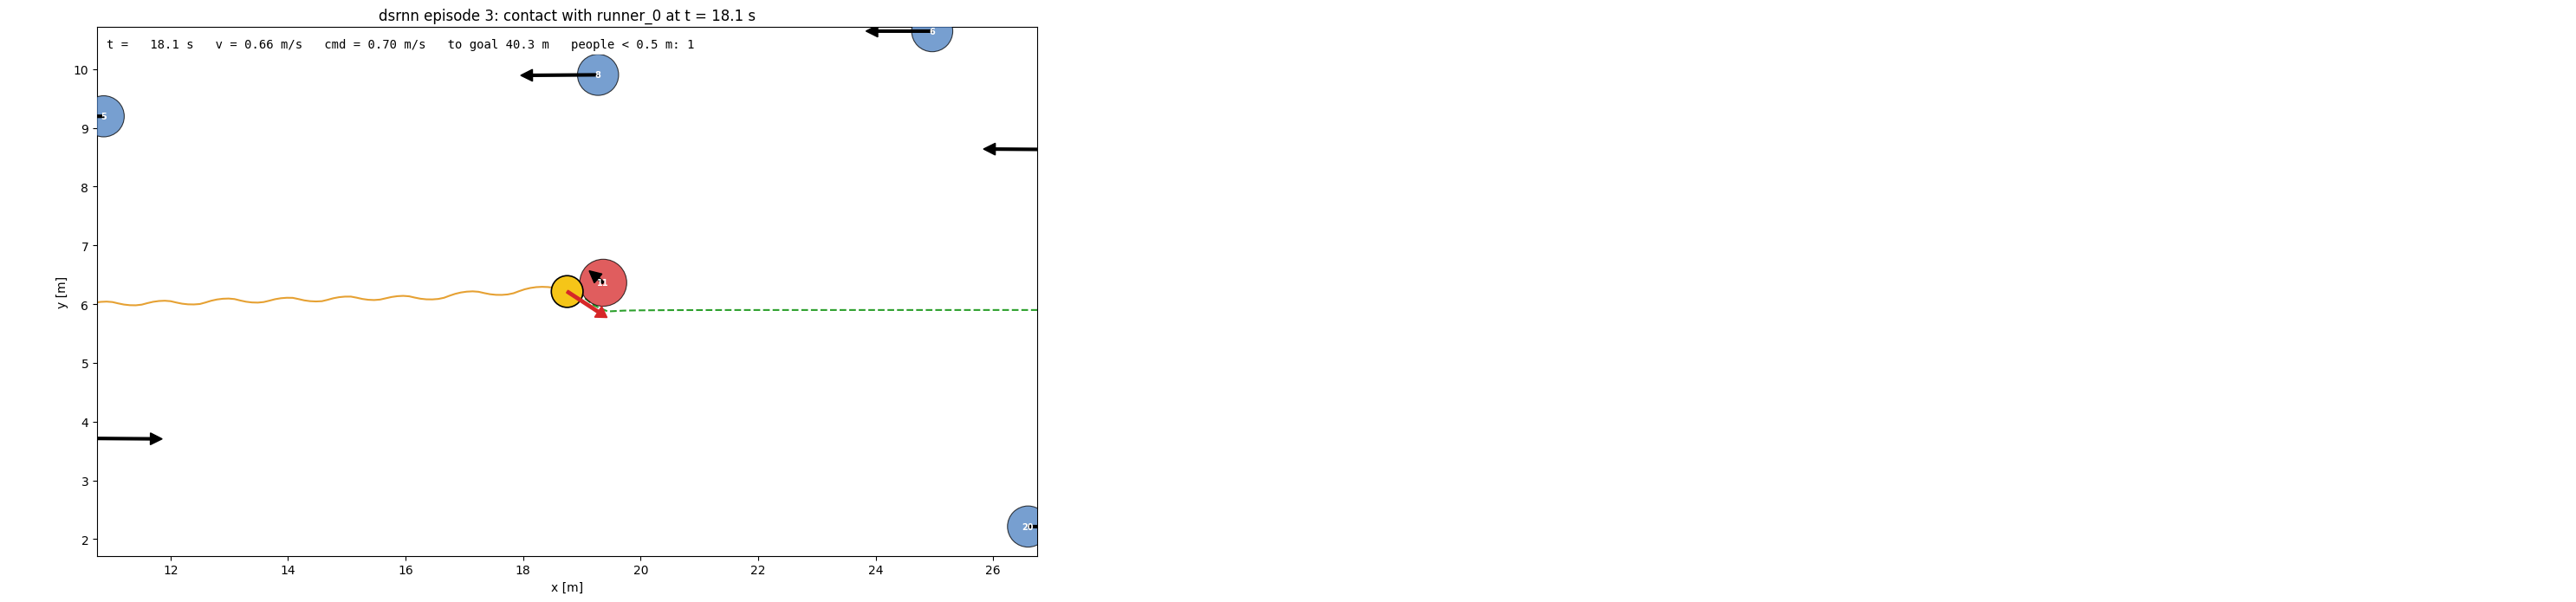

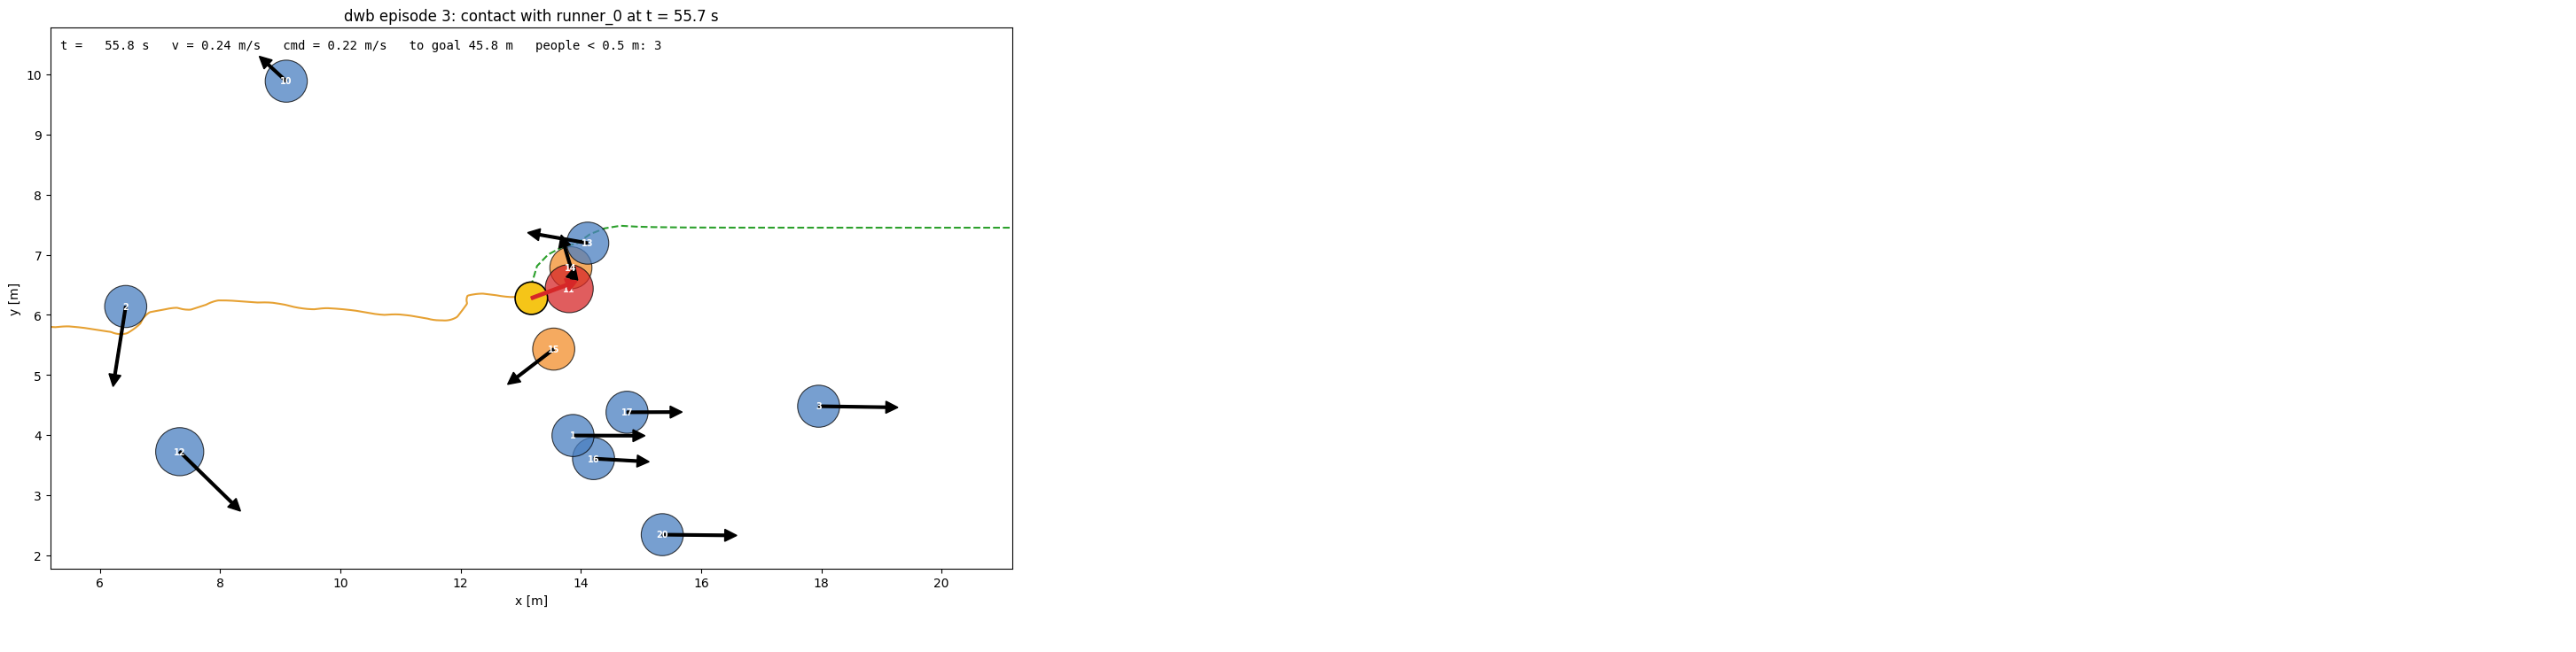

In [16]:
for planner, eps in episodes.items():
    c = contacts[contacts.planner == planner]
    if c.empty:
        print(f"{planner}: no contacts")
        continue
    first = c.sort_values(["episode", "t_rel"]).iloc[0]
    ep = next(e for e in eps if e.meta["episode"] == first.episode)
    ax = ep.plot(first.t_rel, view="follow")
    ax.set_title(f"{planner} episode {first.episode}: contact with {first['name']} at t = {first.t_rel:.1f} s")
    plt.show()

In [17]:
MEDIA = Path("media"); MEDIA.mkdir(exist_ok=True)

def pick(planner):
    t = table[table.planner == planner]
    typical = t.iloc[(t.time_to_goal - t.time_to_goal.median()).abs().argsort().iloc[0]]
    worst = t.sort_values(["collisions", "min_clearance"], ascending=[False, True]).iloc[0]
    return {"typical": int(typical.episode), "worst": int(worst.episode)}

videos = []
for planner, eps in episodes.items():
    for label, i in pick(planner).items():
        ep = next(e for e in eps if e.meta["episode"] == i)
        out = MEDIA / f"{planner}_{label}_ep{i:03d}.mp4"
        if not out.exists():
            ep.save_video(out, speed=8 if planner == "dsrnn" else 16, fps=10)
        videos.append((planner, label, i, out))
for planner, label, i, out in videos:
    print(f"{planner} {label} (episode {i}):")
    display(Video(str(out), embed=False, width=900))

dsrnn typical (episode 3):


dsrnn worst (episode 5):


dwb typical (episode 6):


dwb worst (episode 8):


To watch any episode in the notebook yourself:

```python
ep = episodes["dwb"][3]
ep.play(speed=8)                 # inline video
ep.play(speed=4, view="follow")  # zoomed in on the robot
ep.plot(42.0)                    # one frame, 42 s into the episode
```

## 11. Takeaways (run of 2026-10-11)

**Task.** DS-RNN succeeded 19/20, DWB 20/20.
- DS-RNN's one failure is the **end-wall trap**: it passed ~0.5 m beside the goal (tolerance 0.25 m), overshot
  towards the wall 1 m behind it, and the collision monitor blocked every command, including turning away. Pinned
  for 529 s until the timeout.
- DS-RNN is 3.6× faster (71 s vs 256 s). That's mostly the speed limits (1.0 vs 0.26 m/s), not planning quality.
- DWB drives straighter (path efficiency 0.96 vs 0.89). **Its speed is flat at ~0.23 m/s along the whole hallway** (speed profile): it never slows down for anyone, only steers a little. DS-RNN brakes at encounters and most of its episodes share a large northward detour around x = 20–28 m (path overlay).

**Safety.** Both had contacts in **6/20 episodes (30%)**, the same rate.
- **Every contact was with one of the two runners** (2.7 m/s), and in every one the robot was moving towards the
  runner.
- Nothing else in this scenario ever touched the robot. The runners are about twice as fast as anything in DS-RNN's
  training (0.5–1.5 m/s), and they close distance faster than DWB's lidar-costmap loop reacts.
- Minimum clearance and TTC are statistically indistinguishable between planners.

**Comfort.** DWB spends **16% of its time with someone in their intimate zone** (< 0.45 m) vs DS-RNN's 7%, and
24% vs 13% in the personal zone (both p < 10⁻⁶).
- DWB treats people as costmap obstacles and only avoids what is about to be lethal. It holds its line and lets
  people pass close.
- DS-RNN actively keeps distance, even though it is 4× faster.

**Smoothness.** DS-RNN pays for that with motion quality: 81 turn-direction flips per minute vs 11, 2.5× the jerk,
and 1.7× the turning per metre. That's the bang-bang steering visible in the videos.

**Freezing.** Essentially none.
- DWB never stopped.
- DS-RNN had one 2.6 s freeze next to a person; its other two stops were the wall trap and a brief stop far from
  anyone.

**What this says about the scenario.** It confirms the hunch that this hallway is too easy to discriminate
planners:
- The wide hallway leaves room to swerve, so nobody ever *has* to wait, and nothing provokes freezing.
- The only safety-relevant event type is "runner versus robot".
- Repeating one scenario gives very tight intervals (DWB time to goal 255–258 s), so differences look precise even
  though they only describe this one replayed scene.

Next scenarios should force interaction: narrow corridors, bottlenecks, blocking agents, people who react to the
robot. And they should vary between episodes.

## 12. Ideas for the next experiments

- **Randomise the scenario** (different seeds for `generate_scenario.py`, densities 10/20/40) so the intervals
  describe crowds in general rather than one replayed scene.
- **Same speed limit for both planners** (e.g. both at 0.5 or 1.0 m/s) to separate "faster" from "better".
- **Perception ladder**: DS-RNN with limited range / FOV / occlusion / noise vs perfect perception.
- **Pedestrians that react to the robot** (HuNav robot tracking is currently disabled), then pedestrian
  disturbance metrics: how much people slow down or detour because of the robot.
- **More planners**: CrowdNav++, MPPI, SICNav, same notebook.